# Grupo 2 – SIM | Verificação da base (PC1 + PC2)

**UESB – Aprendizado de Máquina – Laboratório de Dados Públicos em Saúde**

Este notebook levanta, **direto das fontes oficiais**, as informações necessárias para a ficha técnica do SIM e para conferir a viabilidade do problema:

| Seção | O que verifica | Item da planilha |
|---|---|---|
| 1–2 | Estrutura do FTP do DATASUS, arquivos e anos disponíveis (definitivos × preliminares), formato e tamanho | Fonte oficial e documentação; formato |
| 3 | Documentação oficial (dicionário de dados / estrutura do SIM) | Documentação identificada |
| 4 | OpenDataSUS (canal alternativo, CSV) | Mecanismo de acesso |
| 5–6 | Download e leitura dos arquivos da Bahia 2022–2025; dimensões | Dataset obtido; dimensões conferidas |
| 7 | Atributos: tipos, preenchimento, categorias | Atributos descritos |
| 8 | Aplicação dos critérios do estudo (residentes na BA, ≥ 1 ano) e variável-alvo (cap. XX) | Viabilidade do problema |
| 9 | "Ignorado" nos atributos M1–M3 por classe; campos com risco de vazamento | Limitações |
| 10 | Mapeamento município → 28 regiões de saúde (tabelas territoriais do DATASUS) | Atributo territorial |
| 11 | Duplicidades e inconsistências básicas | Limitações |
| 12 | Resumo exportado (CSV/JSON) para a ficha técnica | — |

**Como usar:** `Ambiente de execução → Executar tudo`. Leva poucos minutos (os arquivos da BA têm alguns MB por ano).
Os resultados ficam em `/content/sim_verificacao/saidas/` e são compactados num `.zip` ao final.

> Pergunta de pesquisa: *Qual o ganho de desempenho na discriminação de óbitos por causas externas em relação aos demais óbitos registrados no SIM, entre residentes da Bahia no período de 2022 a 2025, ao acrescentar características demográficas e territoriais a um modelo baseado apenas em sexo e idade?*

## 0. Configuração

In [ ]:
!pip install -q pyreaddbc dbfread

In [ ]:
import os, re, io, json, zipfile, ftplib, datetime, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)

UF = "BA"                     # Bahia
COD_UF_IBGE = "29"            # prefixo dos códigos de município da Bahia
ANOS = [2022, 2023, 2024, 2025]

FTP_HOST = "ftp.datasus.gov.br"
SIM_ROOT = "/dissemin/publicos/SIM"
MIRROR = "https://datasus-ftp-mirror.nyc3.cdn.digitaloceanspaces.com"  # espelho público do FTP (fallback)

BASE = Path("/content/sim_verificacao") if Path("/content").exists() else Path("sim_verificacao")
DIR_BRUTO = BASE / "brutos"; DIR_DOCS = BASE / "docs"; DIR_TERR = BASE / "territorio"; DIR_OUT = BASE / "saidas"
for d in (DIR_BRUTO, DIR_DOCS, DIR_TERR, DIR_OUT):
    d.mkdir(parents=True, exist_ok=True)

RESUMO = {"data_verificacao": datetime.datetime.now().isoformat(timespec="seconds"),
          "uf": UF, "anos_pedidos": ANOS}
print("Pastas em:", BASE.resolve())

Pastas em: /content/sim_verificacao


## 1. Estrutura do FTP do DATASUS

Lista o que existe em `/dissemin/publicos/SIM` para registrar o **mecanismo de acesso oficial** e localizar as pastas de dados **definitivos** (`CID10/DORES`) e **preliminares** (`PRELIM/...`).

In [ ]:
def ftp_conectar():
    ftp = ftplib.FTP(FTP_HOST, timeout=120)
    ftp.login()
    ftp.encoding = "latin-1"
    return ftp

COLS_LISTA = ["nome", "tipo", "bytes", "modificado", "caminho"]

def interpretar_linha_list(b):
    # Interpreta uma linha do comando LIST (formato Windows/IIS ou Unix). Nomes podem ter espaços.
    b = b.rstrip()
    if not b:
        return None
    if re.match(r"^\d{2}-\d{2}-\d{2,4}", b):            # IIS:  11-20-23  10:30AM  <DIR>  nome com espaço
        partes = b.split(None, 3)
        if len(partes) < 4:
            return None
        return partes[3], ("dir" if partes[2].upper() == "<DIR>" else "arquivo")
    partes = b.split(None, 8)                              # Unix: drwxr-xr-x 1 owner group 0 Nov 20 10:30 nome
    if len(partes) < 9:
        return None
    return partes[8], ("dir" if b.startswith("d") else "arquivo")

def ftp_listar(ftp, caminho, detalhar=r".*"):
    # Lista um diretório; para arquivos cujo nome casa com `detalhar`, busca tamanho (bytes) e data de modificação.
    try:
        ftp.cwd(caminho)
    except ftplib.error_perm as e:
        print(f"[não existe] {caminho}: {e}")
        return pd.DataFrame(columns=COLS_LISTA)
    brutas = []
    ftp.retrlines("LIST", brutas.append)
    linhas = []
    for b in brutas:
        item = interpretar_linha_list(b)
        if item is None:
            continue
        nome, tipo = item
        if nome in (".", ".."):
            continue
        tam, mod = None, None
        if tipo == "arquivo" and re.search(detalhar, nome, re.I):
            try:
                ftp.voidcmd("TYPE I")
                tam = ftp.size(nome)
            except Exception:
                pass
            try:
                r = ftp.voidcmd(f"MDTM {nome}")
                mod = datetime.datetime.strptime(r.split()[1][:14], "%Y%m%d%H%M%S")
            except Exception:
                pass
        linhas.append({"nome": nome, "tipo": tipo, "bytes": tam, "modificado": mod, "caminho": f"{caminho}/{nome}"})
    return pd.DataFrame(linhas, columns=COLS_LISTA)

ftp = ftp_conectar()
print("Conectado a", FTP_HOST, "|", ftp.getwelcome()[:80])
raiz_sim = ftp_listar(ftp, SIM_ROOT)
display(raiz_sim)

# subpastas de interesse (navega um nível abaixo de cada pasta do SIM)
arvore = {}
for _, r in raiz_sim[raiz_sim.tipo == "dir"].iterrows():
    sub = ftp_listar(ftp, r.caminho, detalhar=r"^$")  # só nomes (rápido)
    arvore[r.nome] = sub[["nome", "tipo"]].to_dict("records")
    print(f"\n{r.caminho}:", ", ".join(sub.nome.tolist()) or "(vazia ou inacessível)")
RESUMO["ftp_estrutura_sim"] = arvore

Conectado a ftp.datasus.gov.br | 220 Microsoft FTP Service


,nome,tipo,bytes,modificado,caminho
0,1996_,dir,None,None,/dissemin/publicos/SIM/1996_
1,1997_1995,dir,None,None,/dissemin/publicos/SIM/1997_1995
2,CID10,dir,None,None,/dissemin/publicos/SIM/CID10
3,CID9,dir,None,None,/dissemin/publicos/SIM/CID9
4,PRELIM,dir,None,None,/dissemin/publicos/SIM/PRELIM



/dissemin/publicos/SIM/1996_: (vazia ou inacessível)

/dissemin/publicos/SIM/1997_1995: (vazia ou inacessível)

/dissemin/publicos/SIM/CID10: DOCS, DOFET, DORES, TAB, TABELAS

/dissemin/publicos/SIM/CID9: DOCS, DOFET, DOIGN, DORES, TAB, TABELAS

/dissemin/publicos/SIM/PRELIM: DOFET, DORES


## 2. Arquivos de óbitos da Bahia disponíveis

Procura `DO{UF}{ANO}.dbc` (padrão do DATASUS) nas pastas de dados definitivos e preliminares. O status de cada ano (definitivo/preliminar) é determinado pela **pasta em que o arquivo está**.
Obs.: `DORES` = Declarações de Óbito **por residência** — o arquivo `DOBA` reúne os residentes na Bahia, inclusive os que morreram em outros estados.

In [ ]:
PASTAS_CANDIDATAS = {
    "definitivo": [f"{SIM_ROOT}/CID10/DORES"],
    "preliminar": [f"{SIM_ROOT}/PRELIM/DORES", f"{SIM_ROOT}/PRELIM/DOR", f"{SIM_ROOT}/PRELIM"],
}
padrao = re.compile(rf"^DO{UF}(\d{{4}})\.dbc$", re.I)

registros = []
for status, pastas in PASTAS_CANDIDATAS.items():
    for pasta in pastas:
        lst = ftp_listar(ftp, pasta, detalhar=rf"^DO{UF}\d{{4}}\.dbc$")
        if lst.empty:
            continue
        for _, r in lst.iterrows():
            m = padrao.match(r.nome)
            if m:
                registros.append({"ano": int(m.group(1)), "status": status, "arquivo": r.nome,
                                  "bytes": r.bytes, "modificado": r.modificado, "caminho": r.caminho})
        if any(x["status"] == status for x in registros):
            break  # achou a pasta certa desse status

disp = pd.DataFrame(registros, columns=["ano", "status", "arquivo", "bytes", "modificado", "caminho"]).sort_values(["ano", "status"]).reset_index(drop=True)
print(f"Arquivos DO{UF}*.dbc encontrados (todos os anos):")
display(disp)

# Para cada ano pedido, prioriza o definitivo
escolhidos = (disp[disp.ano.isin(ANOS)]
              .assign(prio=lambda d: d.status.map({"definitivo": 0, "preliminar": 1}))
              .sort_values(["ano", "prio"]).drop_duplicates("ano").drop(columns="prio"))
faltando = sorted(set(ANOS) - set(escolhidos.ano))
print("\nArquivos que serão usados:")
display(escolhidos)
if faltando:
    print("⚠️ Anos sem arquivo no FTP:", faltando)

RESUMO["anos_disponiveis_ftp"] = {
    "definitivos": sorted(disp[disp.status == "definitivo"].ano.unique().tolist()),
    "preliminares": sorted(disp[disp.status == "preliminar"].ano.unique().tolist()),
}
RESUMO["arquivos_usados"] = escolhidos.assign(modificado=escolhidos.modificado.astype(str)).to_dict("records")
RESUMO["anos_faltando"] = faltando

Arquivos DOBA*.dbc encontrados (todos os anos):


,ano,status,arquivo,bytes,modificado,caminho
0,1996,definitivo,DOBA1996.dbc,1624514.0,2020-01-31 17:48:48,/dissemin/publicos/SIM/CID10/DORES/DOBA1996.dbc
1,1997,definitivo,DOBA1997.dbc,1578042.0,2020-01-31 17:48:48,/dissemin/publicos/SIM/CID10/DORES/DOBA1997.dbc
2,1998,definitivo,DOBA1998.dbc,1744671.0,2020-01-31 17:48:48,/dissemin/publicos/SIM/CID10/DORES/DOBA1998.dbc
3,1999,definitivo,DOBA1999.dbc,2409197.0,2020-01-31 17:48:48,/dissemin/publicos/SIM/CID10/DORES/DOBA1999.dbc
4,2000,definitivo,DOBA2000.dbc,2437418.0,2020-01-31 17:48:49,/dissemin/publicos/SIM/CID10/DORES/DOBA2000.dbc
5,2001,definitivo,DOBA2001.dbc,2437657.0,2020-01-31 17:48:49,/dissemin/publicos/SIM/CID10/DORES/DOBA2001.dbc
6,2002,definitivo,DOBA2002.dbc,2688926.0,2020-01-31 17:48:49,/dissemin/publicos/SIM/CID10/DORES/DOBA2002.dbc
7,2003,definitivo,DOBA2003.dbc,2724558.0,2020-01-31 17:48:50,/dissemin/publicos/SIM/CID10/DORES/DOBA2003.dbc
8,2004,definitivo,DOBA2004.dbc,2770118.0,2020-01-31 17:48:50,/dissemin/publicos/SIM/CID10/DORES/DOBA2004.dbc
9,2005,definitivo,DOBA2005.dbc,2803117.0,2020-01-31 17:48:50,/dissemin/publicos/SIM/CID10/DORES/DOBA2005.dbc



Arquivos que serão usados:


,ano,status,arquivo,bytes,modificado,caminho
26,2022,definitivo,DOBA2022.dbc,8510675.0,2023-12-21 19:17:56,/dissemin/publicos/SIM/CID10/DORES/DOBA2022.dbc
27,2023,definitivo,DOBA2023.dbc,8746195.0,2024-12-19 14:54:25,/dissemin/publicos/SIM/CID10/DORES/DOBA2023.dbc
28,2024,definitivo,DOBA2024.dbc,9182167.0,2025-12-23 18:46:25,/dissemin/publicos/SIM/CID10/DORES/DOBA2024.dbc
29,2025,preliminar,DOBA2025.dbc,8452456.0,2026-08-28 16:39:26,/dissemin/publicos/SIM/PRELIM/DORES/DOBA2025.dbc


## 3. Documentação oficial

Baixa os documentos publicados junto com os dados (dicionário/estrutura do SIM, notas técnicas). Esses arquivos são a **referência oficial dos atributos e códigos** que vai na ficha técnica.

In [ ]:
docs = pd.DataFrame()
for pasta in [f"{SIM_ROOT}/CID10/DOCS", f"{SIM_ROOT}/DOCS", f"{SIM_ROOT}/PRELIM/DOCS"]:
    lst = ftp_listar(ftp, pasta)
    if not lst.empty:
        lst["pasta"] = pasta
        docs = pd.concat([docs, lst[lst.tipo == "arquivo"]], ignore_index=True)

display(docs[["pasta", "nome", "bytes", "modificado"]] if not docs.empty else "Nenhuma pasta DOCS encontrada")

baixados = []
for _, r in docs.iterrows():
    destino = DIR_DOCS / r.nome
    if not destino.exists():
        try:
            ftp.voidcmd("TYPE I")
            with open(destino, "wb") as f:
                ftp.retrbinary(f"RETR {r.caminho}", f.write)
        except Exception as e:
            print("falhou:", r.caminho, e); continue
    baixados.append(r.caminho)
print(f"\n{len(baixados)} documento(s) salvos em {DIR_DOCS}")
RESUMO["documentacao_ftp"] = baixados

[não existe] /dissemin/publicos/SIM/DOCS: 550 The system cannot find the file specified. 
[não existe] /dissemin/publicos/SIM/PRELIM/DOCS: 550 The system cannot find the file specified. 


,pasta,nome,bytes,modificado
0,/dissemin/publicos/SIM/CID10/DOCS,Docs_Tabs_CID10.zip,2301039,2018-06-05 19:26:59
1,/dissemin/publicos/SIM/CID10/DOCS,Estrutura_do_SIM_2025.pdf,634146,2025-07-07 14:02:26
2,/dissemin/publicos/SIM/CID10/DOCS,Estrutura_SIM_Anterior.pdf,55572,2011-08-24 15:14:40
3,/dissemin/publicos/SIM/CID10/DOCS,Estrutura_SIM_para_CD.pdf,435397,2020-03-11 17:48:46
4,/dissemin/publicos/SIM/CID10/DOCS,Legislacao_PDF.pdf,945786,2011-08-24 15:14:41
5,/dissemin/publicos/SIM/CID10/DOCS,Portaria.pdf,30187,2011-08-24 15:14:42



6 documento(s) salvos em /content/sim_verificacao/docs


## 4. OpenDataSUS (canal alternativo)

Consulta a API do portal de dados abertos para registrar se o SIM também está disponível em CSV e para quais anos.

In [ ]:
import urllib.parse

def opendatasus_buscar(termo="SIM mortalidade"):
    url = "https://opendatasus.saude.gov.br/api/3/action/package_search?rows=20&q=" + urllib.parse.quote(termo)
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0", "Accept": "application/json"})
    with urllib.request.urlopen(req, timeout=60) as resp:
        corpo = resp.read()
    try:
        return json.loads(corpo)
    except json.JSONDecodeError:
        raise RuntimeError(f"resposta não-JSON do portal (início: {corpo[:120]!r})")

try:
    res = opendatasus_buscar()
    linhas = []
    for pkg in res["result"]["results"]:
        for rec in pkg.get("resources", []):
            linhas.append({"conjunto": pkg.get("title"), "recurso": rec.get("name"),
                           "formato": rec.get("format"), "url": rec.get("url"),
                           "atualizado": rec.get("last_modified") or rec.get("created")})
    ods = pd.DataFrame(linhas)
    ods_sim = ods[ods.conjunto.str.contains("SIM|Mortalidade", case=False, na=False)]
    display(ods_sim)
    RESUMO["opendatasus"] = ods_sim.to_dict("records")
except Exception as e:
    print("Não foi possível consultar o OpenDataSUS agora:", e)
    RESUMO["opendatasus"] = f"erro: {e}"

Não foi possível consultar o OpenDataSUS agora: resposta não-JSON do portal (início: b'<!DOCTYPE html><html lang="en"><head><meta charSet="utf-8" data-next-head=""/><meta name="viewport" content="width=devic')


## 5. Download dos arquivos da Bahia (2022–2025)

Baixa via FTP; se falhar, tenta o espelho público do FTP.

In [ ]:
def baixar(caminho_remoto, destino):
    if destino.exists() and destino.stat().st_size > 0:
        return "cache"
    try:
        f = ftp_conectar()
        f.voidcmd("TYPE I")
        with open(destino, "wb") as out:
            f.retrbinary(f"RETR {caminho_remoto}", out.write)
        f.quit()
        return "ftp"
    except Exception as e:
        print(f"FTP falhou ({e}); tentando espelho...")
        urllib.request.urlretrieve(MIRROR + caminho_remoto, destino)
        return "espelho"

for _, r in escolhidos.iterrows():
    origem = baixar(r.caminho, DIR_BRUTO / r.arquivo)
    print(f"{r.arquivo:<14} {r.status:<11} {(DIR_BRUTO / r.arquivo).stat().st_size/1e6:6.2f} MB  ({origem})")

DOBA2022.dbc   definitivo    8.51 MB  (ftp)
DOBA2023.dbc   definitivo    8.75 MB  (ftp)
DOBA2024.dbc   definitivo    9.18 MB  (ftp)
DOBA2025.dbc   preliminar    8.45 MB  (ftp)


## 6. Leitura e dimensões

Formato original: **`.dbc`** (DBF comprimido, formato proprietário do DATASUS). Conversão `.dbc → .dbf` com `pyreaddbc` e leitura com `dbfread`. Todas as colunas são lidas como **texto**, preservando os códigos originais (zeros à esquerda, códigos de "ignorado").

In [ ]:
import pyreaddbc
from dbfread import DBF

def ler_dbc(caminho_dbc):
    dbf = caminho_dbc.with_suffix(".dbf")
    if not dbf.exists():
        pyreaddbc.dbc2dbf(str(caminho_dbc), str(dbf))
    tabela = DBF(str(dbf), encoding="iso-8859-1", char_decode_errors="replace", load=False)
    df = pd.DataFrame(iter(tabela))
    return df.astype("string"), list(tabela.field_names)

partes, colunas_por_ano, dims = [], {}, []
for _, r in escolhidos.iterrows():
    df_ano, campos = ler_dbc(DIR_BRUTO / r.arquivo)
    df_ano["ANO_ARQUIVO"] = r.ano
    df_ano["STATUS_ARQUIVO"] = r.status
    colunas_por_ano[r.ano] = campos
    dims.append({"ano": r.ano, "status": r.status, "registros": len(df_ano), "colunas": len(campos),
                 "MB_dbc": round((DIR_BRUTO / r.arquivo).stat().st_size / 1e6, 2)})
    partes.append(df_ano)

sim = pd.concat(partes, ignore_index=True)
dims = pd.DataFrame(dims)
display(dims)
print("\nTOTAL:", f"{len(sim):,}".replace(",", "."), f"registros × {sim.shape[1]-2} colunas originais")
RESUMO["dimensoes_por_ano"] = dims.to_dict("records")
RESUMO["total_registros_brutos"] = int(len(sim))

,ano,status,registros,colunas,MB_dbc
0,2022,definitivo,107641,87,8.51
1,2023,definitivo,103081,87,8.75
2,2024,definitivo,106212,87,9.18
3,2025,preliminar,106299,87,8.45



TOTAL: 423.233 registros × 87 colunas originais


In [ ]:
# As colunas mudam entre os anos?
todas = sorted(set().union(*colunas_por_ano.values()))
presenca = pd.DataFrame({ano: [c in cols for c in todas] for ano, cols in colunas_por_ano.items()}, index=todas)
diferentes = presenca[~presenca.all(axis=1)]
print(f"{len(todas)} colunas distintas no período; {len(diferentes)} não aparecem em todos os anos.")
display(diferentes if len(diferentes) else "Mesma estrutura em todos os anos.")
RESUMO["colunas_nao_comuns"] = diferentes.reset_index(names="coluna").to_dict("records")

87 colunas distintas no período; 0 não aparecem em todos os anos.


'Mesma estrutura em todos os anos.'

## 7. Atributos: preenchimento e categorias

Perfil de **todas** as colunas (preenchimento, nº de categorias, exemplos) e, em seguida, as distribuições das variáveis do estudo **com os códigos brutos**. Conferir os rótulos com o dicionário baixado na Seção 3.

In [ ]:
def vazio(s):
    return s.isna() | (s.str.strip() == "")

perfil = pd.DataFrame({
    "preenchido_%": [(~vazio(sim[c])).mean() * 100 for c in todas],
    "n_categorias": [sim[c].nunique(dropna=True) for c in todas],
    "exemplos": [", ".join(sim[c].dropna().astype(str).value_counts().index[:5]) for c in todas],
}, index=todas).round(1)
display(perfil)
perfil.to_csv(DIR_OUT / "perfil_todas_colunas.csv")

,preenchido_%,n_categorias,exemplos
ACIDTRAB,3.7,4,", 2, 9, 1"
ALTCAUSA,1.7,3,", 2, 1"
ASSISTMED,45.3,4,", 1, 2, 9"
ATESTADO,100.0,246282,"R99, R99X/ / / /, I219, R99*I10, I10"
ATESTANTE,89.1,6,"1, 5, 2, 3,"
...,...,...,...
TPOBITOCOR,3.6,10,", 9, 8, 5, 6"
TPPOS,44.7,3,", N, S"
TPRESGINFO,0.1,4,", 1, 3, 2"
VERSAOSCB,99.5,6,"3.4, 4.3, 3.3, 3.2,"


In [ ]:
VARS_ESTUDO = ["CAUSABAS", "CODMUNRES", "CODMUNOCOR", "DTOBITO", "IDADE", "SEXO",
               "RACACOR", "ESC", "ESC2010", "ESCFALAGR1", "SERIESCFAL", "ESTCIV",
               "CIRCOBITO", "ACIDTRAB", "FONTE", "LOCOCOR", "ASSISTMED", "NECROPSIA", "TIPOBITO"]
presentes = [v for v in VARS_ESTUDO if v in sim.columns]
print("Variáveis de interesse ausentes nesta base:", sorted(set(VARS_ESTUDO) - set(presentes)) or "nenhuma")

for v in ["SEXO", "RACACOR", "ESC", "ESC2010", "ESTCIV", "TIPOBITO"]:
    if v in sim.columns:
        vc = sim[v].fillna("<vazio>").value_counts()
        print(f"\n== {v} ==")
        display(pd.DataFrame({"n": vc, "%": (vc / vc.sum() * 100).round(2)}))

Variáveis de interesse ausentes nesta base: nenhuma

== SEXO ==


,n,%
SEXO,,
1,240236,56.76
2,182800,43.19
0,197,0.05



== RACACOR ==


,n,%
RACACOR,,
4,248294,58.67
1,85489,20.2
2,73425,17.35
,13375,3.16
3,1451,0.34
5,1199,0.28



== ESC ==


,n,%
ESC,,
1,100567,23.76
2,83548,19.74
3,73328,17.33
4,67414,15.93
9,55166,13.03
,27016,6.38
5,16194,3.83


... (2 outputs left out)


== ESTCIV ==


,n,%
ESTCIV,,
1,147574,34.87
2,107036,25.29
3,82241,19.43
9,28899,6.83
,23359,5.52
4,17073,4.03
5,17051,4.03



== TIPOBITO ==


,n,%
TIPOBITO,,
2,423233,100.0


## 8. Critérios do estudo e variável-alvo

**Idade (`IDADE`)** – código de 3 dígitos: o 1º dígito é a unidade (0 = minutos, 1 = horas, 2 = dias, 3 = meses, 4 = anos, 5 = 100 anos ou mais) e os 2 seguintes, a quantidade. Conferir no dicionário.

**Alvo** – `CAUSABAS` entre **V01 e Y98** (Capítulo XX da CID-10) = 1; demais = 0.

**Critérios** – residentes na Bahia (`CODMUNRES` começando com 29), óbitos não fetais (arquivo DO), idade ≥ 1 ano.

In [ ]:
def idade_em_anos(cod):
    # Decodifica IDADE do SIM para anos (float). Retorna NaN para ignorado/ inválido.
    cod = pd.Series(cod, dtype="string").str.strip()
    unid = cod.str[0]
    qtd = pd.to_numeric(cod.str[1:3], errors="coerce")
    anos = pd.Series(np.nan, index=cod.index, dtype="float")
    anos[unid == "0"] = qtd[unid == "0"] / (60 * 24 * 365.25)
    anos[unid == "1"] = qtd[unid == "1"] / (24 * 365.25)
    anos[unid == "2"] = qtd[unid == "2"] / 365.25
    anos[unid == "3"] = qtd[unid == "3"] / 12
    anos[unid == "4"] = qtd[unid == "4"]
    anos[unid == "5"] = 100 + qtd[unid == "5"]
    anos[cod.isin(["999", "000"]) | cod.isna()] = np.nan
    return anos

# Capítulos da CID-10 (intervalos de 3 caracteres)
CAPITULOS = [("I","A00","B99"),("II","C00","D48"),("III","D50","D89"),("IV","E00","E90"),("V","F00","F99"),
             ("VI","G00","G99"),("VII","H00","H59"),("VIII","H60","H95"),("IX","I00","I99"),("X","J00","J99"),
             ("XI","K00","K93"),("XII","L00","L99"),("XIII","M00","M99"),("XIV","N00","N99"),("XV","O00","O99"),
             ("XVI","P00","P96"),("XVII","Q00","Q99"),("XVIII","R00","R99"),("XIX","S00","T98"),
             ("XX","V01","Y98"),("XXI","Z00","Z99"),("XXII","U00","U99")]

def capitulo_cid(cid):
    c = str(cid).strip().upper()[:3]
    for cap, ini, fim in CAPITULOS:
        if ini <= c <= fim:
            return cap
    return "inválido/vazio"

sim["IDADE_ANOS"] = idade_em_anos(sim["IDADE"])
sim["CAPITULO"] = sim["CAUSABAS"].map(capitulo_cid)
sim["ALVO_EXTERNA"] = (sim["CAPITULO"] == "XX").astype(int)

print("Conferência da decodificação da idade (amostra):")
display(sim[["IDADE", "IDADE_ANOS"]].drop_duplicates("IDADE").sample(min(12, sim.IDADE.nunique()), random_state=42).sort_values("IDADE"))

Conferência da decodificação da idade (amostra):


,IDADE,IDADE_ANOS
2542,057,0.000108
8440,109,0.001027
13560,110,0.001141
34760,114,0.001597
16456,123,0.002624
654,405,5.000000
382,409,9.000000
139,481,81.000000
11,486,86.000000
7,499,99.000000


In [ ]:
# Funil de seleção
funil = [("Registros brutos (arquivos DO-BA)", len(sim))]
m_res = sim["CODMUNRES"].str.startswith(COD_UF_IBGE, na=False)
funil.append(("Residentes na Bahia (CODMUNRES 29xxxx)", int(m_res.sum())))
m_idade_ok = sim["IDADE_ANOS"].notna()
funil.append(("… com idade informada", int((m_res & m_idade_ok).sum())))
m_1ano = sim["IDADE_ANOS"] >= 1
base = sim[m_res & m_idade_ok & m_1ano].copy()
funil.append(("… com idade ≥ 1 ano (base do estudo)", len(base)))
m_cid = base["CAPITULO"] != "inválido/vazio"
funil.append(("… com causa básica válida", int(m_cid.sum())))
base = base[m_cid]
funil = pd.DataFrame(funil, columns=["etapa", "registros"])
display(funil)

print("Óbitos de residentes fora da BA registrados nos arquivos da BA:", int((~m_res).sum()))
print("Óbitos de < 1 ano excluídos:", int((m_res & m_idade_ok & ~m_1ano).sum()))
RESUMO["funil"] = funil.to_dict("records")

,etapa,registros
0,Registros brutos (arquivos DO-BA),423233
1,Residentes na Bahia (CODMUNRES 29xxxx),423233
2,… com idade informada,422632
3,… com idade ≥ 1 ano (base do estudo),412692
4,… com causa básica válida,412692


Óbitos de residentes fora da BA registrados nos arquivos da BA: 0
Óbitos de < 1 ano excluídos: 9940


,,obitos,externas,%_externas
ANO_ARQUIVO,STATUS_ARQUIVO,,,
2022,definitivo,104798,13506,12.89
2023,definitivo,100380,13623,13.57
2024,definitivo,103690,13728,13.24
2025,preliminar,103824,12943,12.47


,% dos óbitos
CAPITULO,
IX,26.04
II,15.34
XX,13.04
X,9.92
XVIII,7.93
IV,7.53
XI,5.25
I,5.18
VI,3.09


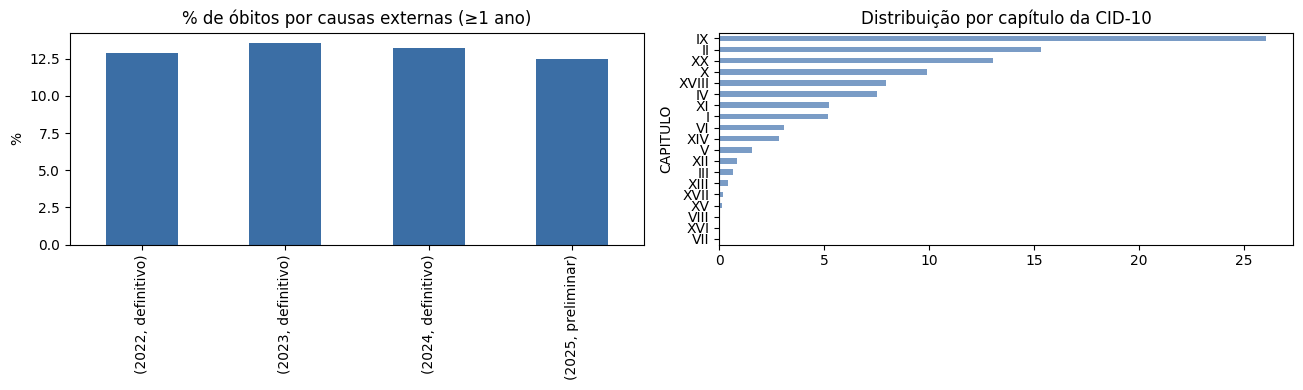

In [ ]:
# Proporção de causas externas por ano e distribuição por capítulo
alvo_ano = base.groupby(["ANO_ARQUIVO", "STATUS_ARQUIVO"]).agg(
    obitos=("ALVO_EXTERNA", "size"), externas=("ALVO_EXTERNA", "sum"))
alvo_ano["%_externas"] = (alvo_ano.externas / alvo_ano.obitos * 100).round(2)
display(alvo_ano)

cap = (base["CAPITULO"].value_counts(normalize=True) * 100).round(2).rename("% dos óbitos")
display(cap.to_frame())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
alvo_ano["%_externas"].plot.bar(ax=ax[0], color="#3b6ea5"); ax[0].set_title("% de óbitos por causas externas (≥1 ano)")
ax[0].set_xlabel(""); ax[0].set_ylabel("%")
cap.sort_values().plot.barh(ax=ax[1], color="#7a9cc6"); ax[1].set_title("Distribuição por capítulo da CID-10")
plt.tight_layout(); plt.savefig(DIR_OUT / "alvo_e_capitulos.png", dpi=150); plt.show()

RESUMO["alvo_por_ano"] = alvo_ano.reset_index().to_dict("records")
RESUMO["pct_externas_total"] = round(base.ALVO_EXTERNA.mean() * 100, 2)
RESUMO["capitulos_pct"] = cap.to_dict()

In [ ]:
# Principais grupos dentro do Capítulo XX (para a caracterização)
GRUPOS_XX = [("Acidentes de transporte","V01","V99"),("Quedas","W00","W19"),("Afogamento","W65","W74"),
             ("Outros acidentes","W20","X59"),("Lesões autoprovocadas (suicídio)","X60","X84"),
             ("Agressões (homicídio)","X85","Y09"),("Intenção indeterminada","Y10","Y34"),
             ("Intervenção legal/guerra","Y35","Y36"),("Complicações assist. médica","Y40","Y84"),
             ("Sequelas e outros","Y85","Y98")]
def grupo_xx(cid):
    c = str(cid)[:3]
    for nome, ini, fim in GRUPOS_XX:
        if ini <= c <= fim:
            return nome
    return "outro"
ext = base[base.ALVO_EXTERNA == 1]
gxx = (ext["CAUSABAS"].map(grupo_xx).value_counts(normalize=True) * 100).round(2)
display(gxx.to_frame("% das causas externas"))
RESUMO["grupos_cap_xx_pct"] = gxx.to_dict()

,% das causas externas
CAUSABAS,
Agressões (homicídio),39.23
Acidentes de transporte,21.03
Quedas,8.00
Intenção indeterminada,7.49
Lesões autoprovocadas (suicídio),6.66
Outros acidentes,6.62
Intervenção legal/guerra,6.51
Afogamento,3.50
Complicações assist. médica,0.68


## 9. "Ignorado" por classe e campos com risco de vazamento

Compara o preenchimento dos atributos M1–M3 **entre óbitos por causas externas e demais óbitos**. Diferenças grandes indicam que o padrão de registro (por exemplo, fluxo do IML) pode virar um sinal artificial para o modelo — base do teste de sensibilidade previsto.
Também mostra o preenchimento de campos que **não** serão usados por risco de vazamento.

In [ ]:
CODIGO_IGNORADO = {"SEXO": ["0", "9"], "RACACOR": ["9"], "ESC": ["9"], "ESC2010": ["9"], "ESTCIV": ["9"]}

def pct_ignorado(df, v):
    s = df[v].str.strip()
    return ((s.isna()) | (s == "") | s.isin(CODIGO_IGNORADO.get(v, []))).mean() * 100

atributos = [v for v in ["SEXO", "IDADE", "RACACOR", "ESC", "ESC2010", "ESTCIV", "CODMUNRES"] if v in base.columns]
tab_ign = pd.DataFrame({
    "% ignorado/vazio – causas externas": [pct_ignorado(base[base.ALVO_EXTERNA == 1], v) for v in atributos],
    "% ignorado/vazio – demais óbitos": [pct_ignorado(base[base.ALVO_EXTERNA == 0], v) for v in atributos],
}, index=atributos).round(2)
tab_ign["diferença (p.p.)"] = (tab_ign.iloc[:, 0] - tab_ign.iloc[:, 1]).round(2)
display(tab_ign)
tab_ign.to_csv(DIR_OUT / "ignorados_por_classe.csv")
RESUMO["ignorados_por_classe"] = tab_ign.reset_index(names="variavel").to_dict("records")

VAZAMENTO = [v for v in ["CIRCOBITO", "ACIDTRAB", "FONTE", "ATESTANTE", "LOCOCOR", "ASSISTMED", "NECROPSIA"] if v in base.columns]
tab_vaz = pd.DataFrame({
    "% preenchido – causas externas": [(~vazio(base.loc[base.ALVO_EXTERNA == 1, v])).mean() * 100 for v in VAZAMENTO],
    "% preenchido – demais óbitos": [(~vazio(base.loc[base.ALVO_EXTERNA == 0, v])).mean() * 100 for v in VAZAMENTO],
}, index=VAZAMENTO).round(2)
print("\nCampos excluídos por risco de vazamento (preenchimento por classe):")
display(tab_vaz)
RESUMO["campos_vazamento"] = tab_vaz.reset_index(names="variavel").to_dict("records")

if "ATESTANTE" in base.columns:  # 3 = IML, 4 = SVO (dicionário 2025)
    at = pd.crosstab(base.ATESTANTE.fillna("<vazio>"), base.ALVO_EXTERNA, normalize="columns").mul(100).round(2)
    at.columns = ["% demais óbitos", "% causas externas"]
    print("\nATESTANTE (1 assistente, 2 substituto, 3 IML, 4 SVO, 5 outro) por classe:")
    display(at)
    RESUMO["atestante_por_classe"] = at.reset_index().to_dict("records")

,% ignorado/vazio – causas externas,% ignorado/vazio – demais óbitos,diferença (p.p.)
SEXO,0.00,0.01,-0.01
IDADE,0.00,0.00,0.00
RACACOR,1.59,3.11,-1.52
ESC,16.82,17.44,-0.62
ESC2010,16.94,18.15,-1.21
ESTCIV,10.62,10.04,0.58
CODMUNRES,0.00,0.00,0.00



Campos excluídos por risco de vazamento (preenchimento por classe):


,% preenchido – causas externas,% preenchido – demais óbitos
CIRCOBITO,99.82,0.00
ACIDTRAB,28.68,0.00
FONTE,84.58,0.00
ATESTANTE,97.78,87.75
LOCOCOR,100.00,100.00
ASSISTMED,65.45,42.36
NECROPSIA,81.83,52.13



ATESTANTE (1 assistente, 2 substituto, 3 IML, 4 SVO, 5 outro) por classe:


,% demais óbitos,% causas externas
ATESTANTE,,
,12.25,2.22
1,34.14,4.57
2,15.61,2.23
3,3.01,86.38
4,1.97,0.69
5,33.02,3.90


## 10. Território: município → região de saúde

Busca as **tabelas territoriais oficiais do DATASUS** (`/territorio/tabelas`, um pacote por ano), baixa o mais recente e localiza a relação município × região de saúde. Os códigos de município do SIM têm **6 dígitos**; os do IBGE têm 7 (o 7º é dígito verificador).

In [ ]:
# 10.1 Varre /territorio/tabelas (subpastas por ano) e baixa o pacote mais recente
def ftp_varrer(ftp, caminho, prof=0, max_prof=2):
    lst = ftp_listar(ftp, caminho, detalhar=r"\.(zip|rar|dbf|csv)$")
    out = []
    for _, r in lst.iterrows():
        if r.tipo == "dir" and prof < max_prof:
            out += ftp_varrer(ftp, r.caminho, prof + 1, max_prof)
        elif r.tipo == "arquivo":
            out.append(r.to_dict())
    return out

terr = pd.DataFrame(ftp_varrer(ftp, "/territorio/tabelas"), columns=COLS_LISTA)
terr.to_csv(DIR_OUT / "territorio_listagem_ftp.csv", index=False)
print(f"{len(terr)} arquivo(s) em /territorio/tabelas (até 2 níveis):")
display(terr[["caminho", "bytes", "modificado"]].tail(30))

def ano_no_nome(c):
    anos = re.findall(r"(20\d{2})", c)
    return int(anos[-1]) if anos else 0

pacotes = terr[terr.nome.str.lower().str.endswith(".zip")].copy()
pacotes["ano_ref"] = pacotes.caminho.map(ano_no_nome)
pacotes = pacotes.sort_values(["ano_ref", "modificado"], na_position="first")
escolhido_terr = pacotes.tail(1)
print("\nPacote escolhido (mais recente):")
display(escolhido_terr[["caminho", "bytes", "modificado"]])

def extrair_tudo(zip_path, destino):
    # Extrai um zip e, recursivamente, zips internos.
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(destino)
    for interno in list(Path(destino).rglob("*.zip")):
        if interno != zip_path:
            extrair_tudo(interno, interno.with_suffix(""))
            interno.unlink()

for _, r in escolhido_terr.iterrows():
    destino = DIR_TERR / Path(r.nome).name
    if not destino.exists():
        ftp.voidcmd("TYPE I")
        with open(destino, "wb") as f:
            ftp.retrbinary(f"RETR {r.caminho}", f.write)
    extrair_tudo(destino, DIR_TERR / destino.stem)
    RESUMO["territorio_pacote"] = r.caminho

extraidos = [p for p in DIR_TERR.rglob("*") if p.is_file() and p.suffix.lower() in (".dbf", ".csv", ".txt")]
print(f"\n{len(extraidos)} tabela(s) extraída(s). Relacionadas a região de saúde:")
print([p.name for p in extraidos if re.search("regsaud|macsaud", p.name, re.I)])

21 arquivo(s) em /territorio/tabelas (até 2 níveis):


,caminho,bytes,modificado
0,/territorio/tabelas/2023/base_territorial_2023...,2434673,2023-08-30 15:08:33
1,/territorio/tabelas/2024/02-base_territorio_fe...,1567218,2024-07-02 16:07:50
2,/territorio/tabelas/2024/03-base_territorial_m...,1343397,2024-07-02 14:17:30
3,/territorio/tabelas/2024/04-base_territorial_a...,1334413,2024-07-02 14:17:30
4,/territorio/tabelas/2024/05-base_territorial_m...,1547793,2024-07-02 15:16:21
5,/territorio/tabelas/2024/06-base_territorial_j...,1527995,2024-07-08 15:04:14
6,/territorio/tabelas/2024/07-base_territorial_j...,1692103,2024-07-26 17:45:25
7,/territorio/tabelas/2024/08-base_territorial_a...,1528981,2024-08-16 18:59:08
8,/territorio/tabelas/2024/09-base_territorial_s...,1529003,2024-09-16 16:41:28
9,/territorio/tabelas/2024/10-base_territorial_o...,1606420,2024-10-15 17:09:57



Pacote escolhido (mais recente):


,caminho,bytes,modificado
20,/territorio/tabelas/2026/06-base_territorial_j...,1766516,2026-06-24 13:46:47



84 tabela(s) extraída(s). Relacionadas a região de saúde:
['rl_regsaud_macsaud.dbf', 'tb_macsaud_layout.txt', 'rl_municip_macsaud_layout.txt', 'rl_regsaud_macsaud.txt', 'tb_macsaud.csv', 'rl_municip_regsaud_layout.txt', 'rl_municip_regsaud.csv', 'rl_municip_macsaud.txt', 'rl_municip_regsaud.dbf', 'rl_regsaud_macsaud_layout.txt', 'tb_macsaud.txt', 'rl_municip_regsaud.txt', 'tb_regsaud.csv', 'tb_regsaud.dbf', 'rl_regsaud_macsaud.csv', 'rl_municip_macsaud.dbf', 'tb_regsaud.txt', 'rl_municip_macsaud.csv', 'tb_macsaud.dbf', 'tb_regsaud_layout.txt']


In [ ]:
# 10.2 Relação município × região de saúde e nomes das regiões
def ler_tab(p):
    if p.suffix.lower() == ".dbf":
        return pd.DataFrame(iter(DBF(str(p), encoding="iso-8859-1", load=False))).astype("string")
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(p, sep=None, engine="python", dtype=str, encoding=enc)
        except UnicodeDecodeError:
            continue

def escolher(padrao, excluir=None):
    cands = [p for p in extraidos if re.search(padrao, p.name, re.I) and not (excluir and re.search(excluir, p.name, re.I))]
    cands.sort(key=lambda p: (p.suffix.lower() != ".csv", len(p.name)))  # prefere CSV
    return cands[0] if cands else None

p_rel = escolher(r"rl_municip_regsaud")
p_nom = escolher(r"tb_regsaud")
rel = ler_tab(p_rel) if p_rel else None
nomes = ler_tab(p_nom) if p_nom else None

if rel is not None:
    rel.columns = [c.upper().strip() for c in rel.columns]
    print("Relação:", p_rel.name, rel.shape); display(rel.head())
    col_mun = next(c for c in rel.columns if "MUNIC" in c)
    col_reg = next(c for c in rel.columns if "REGSAUD" in c)
    rel_ba = rel[rel[col_mun].str.startswith(COD_UF_IBGE, na=False)].copy()
    rel_ba["MUN6"] = rel_ba[col_mun].str[:6]
    n_reg = rel_ba[col_reg].nunique()
    print(f"\nRegiões de saúde na BA: {n_reg} | municípios: {rel_ba.MUN6.nunique()}"
          + ("  ✅ (esperado: 28 regiões, 417 municípios)" if n_reg == 28 else "  ⚠️ esperado: 28"))
    mapa = dict(zip(rel_ba.MUN6, rel_ba[col_reg]))
    base["REGIAO_SAUDE"] = base["CODMUNRES"].str[:6].map(mapa)
    sem = base[base.REGIAO_SAUDE.isna()]
    print("Óbitos sem região mapeada:", len(sem), "| códigos:", sem.CODMUNRES.value_counts().head(5).to_dict())

    reg = base.groupby("REGIAO_SAUDE").agg(obitos=("ALVO_EXTERNA", "size"), pct_externas=("ALVO_EXTERNA", "mean"))
    reg["pct_externas"] = (reg.pct_externas * 100).round(2)
    if nomes is not None:
        nomes.columns = [c.upper().strip() for c in nomes.columns]
        cr = next(c for c in nomes.columns if "REGSAUD" in c and ("CO" in c or c == "REGSAUD"))
        cn = next((c for c in nomes.columns if c.startswith(("NO_", "DS_")) or "NOME" in c), None)
        if cn:
            reg = reg.join(nomes.drop_duplicates(cr).set_index(cr)[cn].rename("nome_regiao"))
    display(reg.sort_values("pct_externas", ascending=False))
    reg.to_csv(DIR_OUT / "externas_por_regiao_saude.csv")
    rel_ba.to_csv(DIR_OUT / "municipio_regiao_saude_BA.csv", index=False)
    RESUMO["regioes_saude_ba"] = int(n_reg)
    RESUMO["municipios_ba_na_tabela"] = int(rel_ba.MUN6.nunique())
    RESUMO["obitos_sem_regiao"] = int(len(sem))
else:
    print("⚠️ Tabela rl_municip_regsaud não localizada. Arquivos extraídos:")
    print(sorted(p.name for p in extraidos)[:80])
    RESUMO["regioes_saude_ba"] = "não localizada"
    RESUMO["territorio_arquivos"] = sorted(p.name for p in extraidos)
print("Municípios de residência distintos na base:", base.CODMUNRES.nunique(),
      "(inclui 290000 = município ignorado - BA)" if (base.CODMUNRES == "290000").any() else "")

Relação: rl_municip_regsaud.csv (5572, 2)


,CO_MUNICIP,CO_REGSAUD
0,110002,11001
1,110013,11001
2,110026,11001
3,110040,11001
4,110045,11001



Regiões de saúde na BA: 28 | municípios: 417  ✅ (esperado: 28 regiões, 417 municípios)
Óbitos sem região mapeada: 532 | códigos: {'290000': 532}


,obitos,pct_externas,nome_regiao
REGIAO_SAUDE,,,
29018,10397,18.44,Porto Seguro - BA
29004,14771,16.87,Camaçari - BA
29027,7437,15.96,Valença - BA
29002,10087,15.87,Barreiras - BA
29026,13438,15.37,Teixeira de Freitas - BA
29016,14572,15.04,Juazeiro - BA
29014,11001,13.80,Jacobina - BA
29020,87923,13.77,Salvador - BA
29006,32860,13.17,Feira de Santana - BA


Municípios de residência distintos na base: 418 (inclui 290000 = município ignorado - BA)


## 11. Duplicidades e inconsistências básicas

In [ ]:
cols_orig = [c for c in todas if c in base.columns]
dup_total = int(sim.duplicated(subset=todas).sum())
dup_base = int(base.duplicated(subset=cols_orig).sum())

dt = pd.to_datetime(base["DTOBITO"], format="%d%m%Y", errors="coerce")
incons = {
    "duplicatas exatas (arquivos brutos)": dup_total,
    "duplicatas exatas (base do estudo)": dup_base,
    "DTOBITO inválida": int(dt.isna().sum()),
    "ano de DTOBITO ≠ ano do arquivo": int((dt.dt.year != base.ANO_ARQUIVO).sum()),
    "idade > 110 anos": int((base.IDADE_ANOS > 110).sum()),
    "causa externa com CIRCOBITO vazio": int((base.ALVO_EXTERNA.eq(1) & vazio(base.get("CIRCOBITO", pd.Series(dtype="string")))).sum()) if "CIRCOBITO" in base else None,
    "NUMERODO presente (identificador)": "NUMERODO" in sim.columns,
}
display(pd.Series(incons, name="contagem").to_frame())
print("Códigos de IDADE com mais de 110 anos:", base.loc[base.IDADE_ANOS > 110, "IDADE"].value_counts().head(15).to_dict())
RESUMO["inconsistencias"] = {k: (v if not isinstance(v, (np.integer,)) else int(v)) for k, v in incons.items()}

,contagem
duplicatas exatas (arquivos brutos),0
duplicatas exatas (base do estudo),0
DTOBITO inválida,0
ano de DTOBITO ≠ ano do arquivo,0
idade > 110 anos,227
causa externa com CIRCOBITO vazio,99
NUMERODO presente (identificador),False


Códigos de IDADE com mais de 110 anos: {'511': 70, '512': 42, '513': 41, '515': 19, '514': 17, '516': 11, '517': 10, '519': 6, '518': 4, '523': 2, '522': 2, '521': 2, '520': 1}


## 12. Resumo para a ficha técnica

In [ ]:
def conv(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (pd.Timestamp, datetime.datetime)): return str(o)
    return str(o)

with open(DIR_OUT / "resumo_verificacao.json", "w", encoding="utf-8") as f:
    json.dump(RESUMO, f, ensure_ascii=False, indent=2, default=conv)
dims.to_csv(DIR_OUT / "dimensoes_por_ano.csv", index=False)
funil.to_csv(DIR_OUT / "funil_selecao.csv", index=False)
alvo_ano.to_csv(DIR_OUT / "alvo_por_ano.csv")
disp.to_csv(DIR_OUT / "arquivos_disponiveis_ftp.csv", index=False)

print("=" * 70)
print("RESUMO – SIM / Bahia")
print("=" * 70)
print("Verificado em:", RESUMO["data_verificacao"])
print("Anos definitivos no FTP:", RESUMO["anos_disponiveis_ftp"]["definitivos"][-6:])
print("Anos preliminares no FTP:", RESUMO["anos_disponiveis_ftp"]["preliminares"])
print("Anos sem arquivo:", RESUMO["anos_faltando"] or "nenhum")
print(dims.to_string(index=False))
print("Base do estudo (residentes BA, ≥1 ano, causa válida):", f"{len(base):,}".replace(",", "."))
print(f"% causas externas (total): {RESUMO['pct_externas_total']}%")
print("Regiões de saúde mapeadas:", RESUMO.get("regioes_saude_ba"))

arq_zip = BASE / "sim_verificacao_saidas.zip"
with zipfile.ZipFile(arq_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in list(DIR_OUT.glob("*")) + list(DIR_DOCS.glob("*")):
        z.write(p, arcname=f"{p.parent.name}/{p.name}")
print("\nArquivo para download:", arq_zip)
try:
    from google.colab import files
    files.download(str(arq_zip))
except Exception:
    pass
ftp.quit()

RESUMO – SIM / Bahia
Verificado em: 2026-11-16T21:49:10
Anos definitivos no FTP: [2019, 2020, 2021, 2022, 2023, 2024]
Anos preliminares no FTP: [2025, 2026]
Anos sem arquivo: nenhum
 ano     status  registros  colunas  MB_dbc
2022 definitivo     107641       87    8.51
2023 definitivo     103081       87    8.75
2024 definitivo     106212       87    9.18
2025 preliminar     106299       87    8.45
Base do estudo (residentes BA, ≥1 ano, causa válida): 412.692
% causas externas (total): 13.04%
Regiões de saúde mapeadas: 28

Arquivo para download: /content/sim_verificacao/sim_verificacao_saidas.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

'221 Goodbye.'

## 13. Exportar a base em CSV (para o grupo reutilizar)

Gera `sim_BA_2022_2025_bruto.csv.gz` (CSV compactado — o pandas lê direto com `pd.read_csv`): todos os registros e colunas originais dos arquivos DO-BA 2022–2025, como vieram do DATASUS (códigos em texto), + `ANO_ARQUIVO` e `STATUS_ARQUIVO`.

Se `SALVAR_NO_DRIVE = True`, o arquivo vai para `Meu Drive/ML_SIM_G2/dados/` (o Colab pede autorização). Compartilhe essa pasta com o grupo.
Esse arquivo é **intermediário**: não vão para o GitHub. O dataset final (pré-processado) será gerado no PC3.

In [ ]:
SALVAR_NO_DRIVE = True

destino_csv = DIR_OUT / "csv"
if SALVAR_NO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        destino_csv = Path("/content/drive/MyDrive/ML_SIM_G2/dados")
    except Exception as e:
        print("Drive indisponível; salvando localmente:", e)
destino_csv.mkdir(parents=True, exist_ok=True)

arq_bruto = destino_csv / "sim_BA_2022_2025_bruto.csv.gz"
sim.drop(columns=["IDADE_ANOS", "CAPITULO", "ALVO_EXTERNA"], errors="ignore").to_csv(arq_bruto, index=False, encoding="utf-8")
print(f"{arq_bruto.name}  {arq_bruto.stat().st_size/1e6:.2f} MB  → {arq_bruto.parent}")

# Teste de leitura (como o grupo vai abrir depois): tudo como texto preserva os códigos originais
teste = pd.read_csv(arq_bruto, dtype=str, nrows=5)
display(teste)
RESUMO["csv_exportado"] = str(arq_bruto)

Drive indisponível; salvando localmente: Error: credential propagation was unsuccessful
sim_BA_2022_2025_bruto.csv.gz  24.08 MB  → /content/sim_verificacao/saidas/csv


,ORIGEM,TIPOBITO,DTOBITO,HORAOBITO,NATURAL,CODMUNNATU,DTNASC,IDADE,SEXO,RACACOR,ESTCIV,ESC,ESC2010,SERIESCFAL,OCUP,CODMUNRES,LOCOCOR,CODESTAB,ESTABDESCR,CODMUNOCOR,IDADEMAE,ESCMAE,ESCMAE2010,SERIESCMAE,OCUPMAE,QTDFILVIVO,QTDFILMORT,GRAVIDEZ,SEMAGESTAC,GESTACAO,PARTO,OBITOPARTO,PESO,TPMORTEOCO,OBITOGRAV,OBITOPUERP,ASSISTMED,EXAME,CIRURGIA,NECROPSIA,LINHAA,LINHAB,LINHAC,LINHAD,LINHAII,CAUSABAS,CB_PRE,COMUNSVOIM,DTATESTADO,CIRCOBITO,ACIDTRAB,FONTE,NUMEROLOTE,TPPOS,DTINVESTIG,CAUSABAS_O,DTCADASTRO,ATESTANTE,STCODIFICA,CODIFICADO,VERSAOSIST,VERSAOSCB,FONTEINV,DTRECEBIM,ATESTADO,DTRECORIGA,CAUSAMAT,ESCMAEAGR1,ESCFALAGR1,STDOEPIDEM,STDONOVA,DIFDATA,NUDIASOBCO,NUDIASOBIN,DTCADINV,TPOBITOCOR,DTCONINV,FONTES,TPRESGINFO,TPNIVELINV,NUDIASINF,DTCADINF,MORTEPARTO,DTCONCASO,FONTESINF,ALTCAUSA,CONTADOR,ANO_ARQUIVO,STATUS_ARQUIVO
0,1,2,02052022,1400,829,290690,25031951,471,2,2,3,1,0,NaN,999993,291560,3,NaN,NaN,291560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,2,*R688,*E43X,*I64X,*E149,*I10X,I64,NaN,NaN,02052022,NaN,NaN,NaN,20220015,N,NaN,I64,06052022,5,S,S,3.2.02,3.4,NaN,06052022,R688/E43/I64/E149*I10,06052022,NaN,NaN,00,0,1,004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,2022,definitivo
1,1,2,01052022,0920,829,290690,05081952,469,1,2,2,4,3,NaN,999993,291560,1,2556847,NaN,291560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,*R99X,*I10X,NaN,NaN,NaN,I10,NaN,NaN,01052022,NaN,NaN,NaN,20220015,N,NaN,I10,06052022,5,S,S,3.2.02,3.4,NaN,06052022,R99/I10,06052022,NaN,NaN,12,0,1,005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11,2022,definitivo
2,1,2,01052022,1709,829,292550,28051960,461,2,4,1,9,9,NaN,999992,291560,1,2556847,NaN,291560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9,9,9,NaN,NaN,NaN,NaN,*A419,*K830,*E148,*K746,NaN,E148,NaN,NaN,01052022,NaN,NaN,NaN,20220015,N,NaN,E148,06052022,1,S,S,3.2.02,3.4,NaN,06052022,A419/K830/E148/K746,06052022,NaN,NaN,09,0,1,005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12,2022,definitivo
3,1,2,28042022,0701,829,291560,20041953,469,2,4,1,9,9,NaN,999993,291560,1,2556847,NaN,291560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,*R570,*I219,*I10X,NaN,NaN,I219,NaN,NaN,28042022,NaN,NaN,NaN,20220015,N,NaN,I219,06052022,1,S,S,3.2.02,3.4,NaN,06052022,R570/I219/I10,06052022,NaN,NaN,09,0,1,008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13,2022,definitivo
4,1,2,29042022,0420,829,292900,23071930,491,1,2,2,2,1,NaN,999993,291560,3,NaN,NaN,291560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,*R54X,*G409,*N189,*I10X,NaN,G409,NaN,NaN,29042022,NaN,NaN,NaN,20220015,N,NaN,G409,06052022,5,S,S,3.2.02,3.4,NaN,06052022,R54/G409/N189/I10,06052022,NaN,NaN,10,0,1,007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14,2022,definitivo
